# HyperGrid Model Labs - v1
---
Klasifikasi Kondisi Permukaan Jalan & Deteksi Lubang (*Pothole Detection*) berbasis Sensor Inersial Smartphone (Akselerometer & Giroskop) - **Model Versi 1**.

### Pipeline Arsitektur:
1. **Penyelarasan Ground-Truth:** Pemetaan timestamp lubang per perjalanan (*trip-based*).
2. **Invariansi Orientasi:** Ekstraksi magnitudo 3D $\sqrt{x^2+y^2+z^2}$ & Dynamic Acceleration.
3. **Sliding Time Window:** Ekstraksi 32 fitur statistik dan sinyal (*Mean, Std, RMS, Jerk, ZCR, Crest Factor*).
4. **Group-Aware Splitting:** Pengujian pada perjalanan yang benar-benar belum pernah dilihat (*Unseen Trips*).
5. **Ekspor ONNX:** Model mandiri (*standalone*) untuk komputasi tepi (*Edge ML* di Android/iOS).

In [1]:
# 1. Import Dependencies & Path Setup
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster, HeatMap
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve

from utils.dataset import load_raw_trips
from utils.features import RoadFeatureExtractor
from utils.trainer import train_hypergrid_model

print('All libraries and custom modules imported successfully.')

All libraries and custom modules imported successfully.


In [2]:
# 2. Memuat Data Perjalanan & Penyelarasan Label Ground-Truth
trips = load_raw_trips(data_dir='../data', pothole_tolerance_sec=0.75)
print(f'Total Sesi Perjalanan yang Dimuat: {len(trips)} trips')

Total Sesi Perjalanan yang Dimuat: 20 trips


In [3]:
# 3. Ekstraksi Fitur Sinyal Invarian Orientasi (Sliding Window)
extractor = RoadFeatureExtractor(window_size=20, step_size=5)
X, y, groups, metadata = extractor.extract_from_trips(trips)

print('=== HASIL EKSTRAKSI FITUR (v1) ===')
print(f'Matriks Fitur X : {X.shape}')
print(f'Label Target y  : {y.shape}')
print('\nDistribusi Label:')
print(y.value_counts())
print('\nContoh 5 Baris Pertama Fitur:')
X.head()

=== HASIL EKSTRAKSI FITUR (v1) ===
Matriks Fitur X : (4172, 32)
Label Target y  : (4172,)

Distribusi Label:
label
0    3840
1     332
Name: count, dtype: int64

Contoh 5 Baris Pertama Fitur:


,dynamic_acc_mean,dynamic_acc_std,dynamic_acc_min,dynamic_acc_max,dynamic_acc_range,dynamic_acc_rms,gyro_mag_mean,gyro_mag_std,gyro_mag_min,gyro_mag_max,...,angular_jerk_range,angular_jerk_rms,speed_clean_mean,speed_clean_std,speed_clean_min,speed_clean_max,speed_clean_range,speed_clean_rms,dynamic_acc_crest_factor,dynamic_acc_zcr
0,0.008186,0.007174,0.000554,0.025955,0.025400,0.010885,0.031029,0.015965,0.009150,0.065283,...,0.037808,0.017145,0.7025,0.957632,0.00,3.06,3.06,1.187672,2.384179,0.157895
1,0.009908,0.010627,0.000554,0.044747,0.044193,0.014529,0.032750,0.014737,0.015497,0.065283,...,0.027855,0.015448,1.5540,1.419709,0.00,4.79,4.79,2.104873,3.079530,0.105263
2,0.012837,0.010220,0.000554,0.044747,0.044193,0.016408,0.041066,0.021063,0.018302,0.107974,...,0.067028,0.025810,2.9000,1.911214,0.41,6.48,6.07,3.473146,2.726923,0.263158
3,0.020716,0.018090,0.002280,0.085122,0.082842,0.027502,0.066040,0.067426,0.020894,0.340608,...,0.302691,0.095138,4.4050,1.890062,1.47,7.29,5.82,4.793366,3.094977,0.315789
4,0.027535,0.020770,0.002280,0.085122,0.082842,0.034490,0.076186,0.069777,0.020894,0.340608,...,0.302691,0.097412,5.7480,1.640679,3.06,8.23,5.17,5.977569,2.467940,0.105263


In [4]:
# 4. Training Model XGBoost dengan Group-Aware Cross-Validation & Evaluasi Unseen Trips
model_path = '../models/hype_v1.onnx'
results = train_hypergrid_model(
    X=X,
    y=y,
    groups=groups,
    metadata=metadata,
    model_output_path=model_path,
    test_size=0.2,
    random_state=42,
    tune_hyperparameters=True,
)

best_model = results['model']
optimal_threshold = results['optimal_threshold']
results_df = results['results_df']

      HYPERGRID MACHINE LEARNING PIPELINE TRAINING (V1)

1. DATA SPLIT (GROUP-AWARE):
 - Train Samples: 2895 (from 16 trips: ['pothole_trip3', 'pothole_trip4', 'pothole_trip5', 'road_good10', 'road_good1', 'road_good2', 'road_good3', 'road_good4', 'road_good6', 'road_good8', 'road_good9', 'road_bad1', 'road_bad2', 'road_bad3', 'road_bad4', 'road_bad5'])
 - Test Samples : 1277 (from 4 trips: ['pothole_trip1', 'pothole_trip2', 'road_good5', 'road_good7'])
 - Train Pothole Ratio: 6.9%
 - Test Pothole Ratio : 10.3%
 - XGBoost scale_pos_weight: 13.47

2. HYPERPARAMETER TUNING VIA GROUP-K-FOLD...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/Users/zerochirou/Developer/Projects/hypergrid/hg-model/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/zerochirou/Developer/Projects/hypergrid/hg-model/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/zerochirou/Developer/Projects/hypergrid/hg-model/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` 

 - Best CV F1-Score: 0.2843
 - Best Parameters : {'subsample': 0.85, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.85}

3. EVALUASI TEST SET (UNSEEN TRIPS):
 - ROC-AUC Score: 0.8724
 - Optimal Threshold (F1-Tuned): 0.473

--- Classification Report (Default Threshold 0.5) ---
              precision    recall  f1-score   support

      Normal       0.96      0.91      0.93      1145
     Pothole       0.45      0.65      0.53       132

    accuracy                           0.88      1277
   macro avg       0.70      0.78      0.73      1277
weighted avg       0.90      0.88      0.89      1277

--- Classification Report (Optimal Threshold 0.473) ---
              precision    recall  f1-score   support

      Normal       0.96      0.90      0.93      1145
     Pothole       0.45      0.67      0.54       132

    accuracy                           0.88      1277
   macro avg       0.70      0.79      0.73      1277
weighted avg       0.

/var/folders/wr/yfr7rfvd10xbt_gpwcv9_ryh0000gn/T/ipykernel_99561/2037999930.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='viridis')


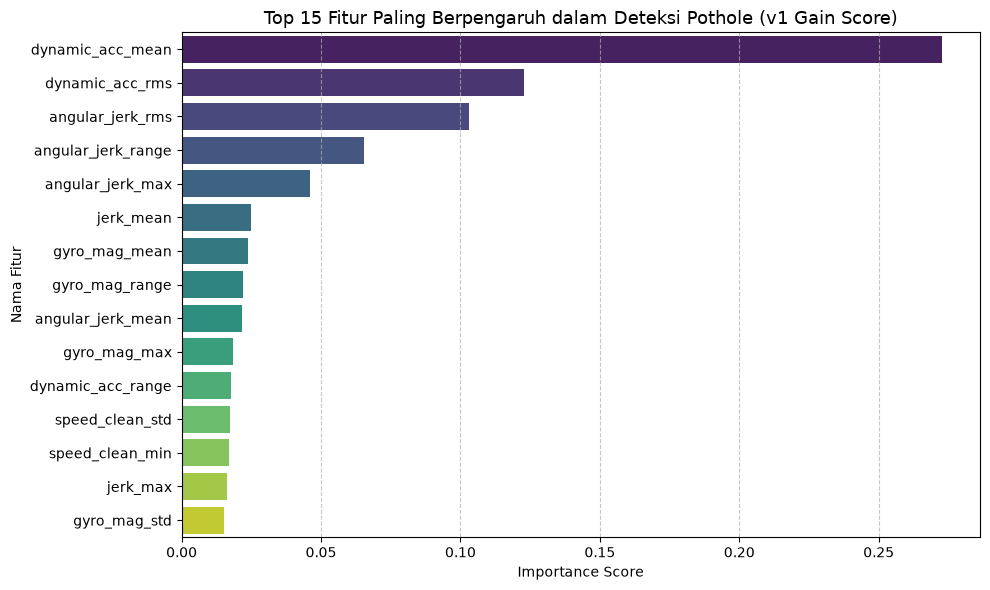

In [5]:
# 5. Visualisasi Feature Importance (Gain)
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='viridis')
plt.title('Top 15 Fitur Paling Berpengaruh dalam Deteksi Pothole (v1 Gain Score)', fontsize=13)
plt.xlabel('Importance Score')
plt.ylabel('Nama Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

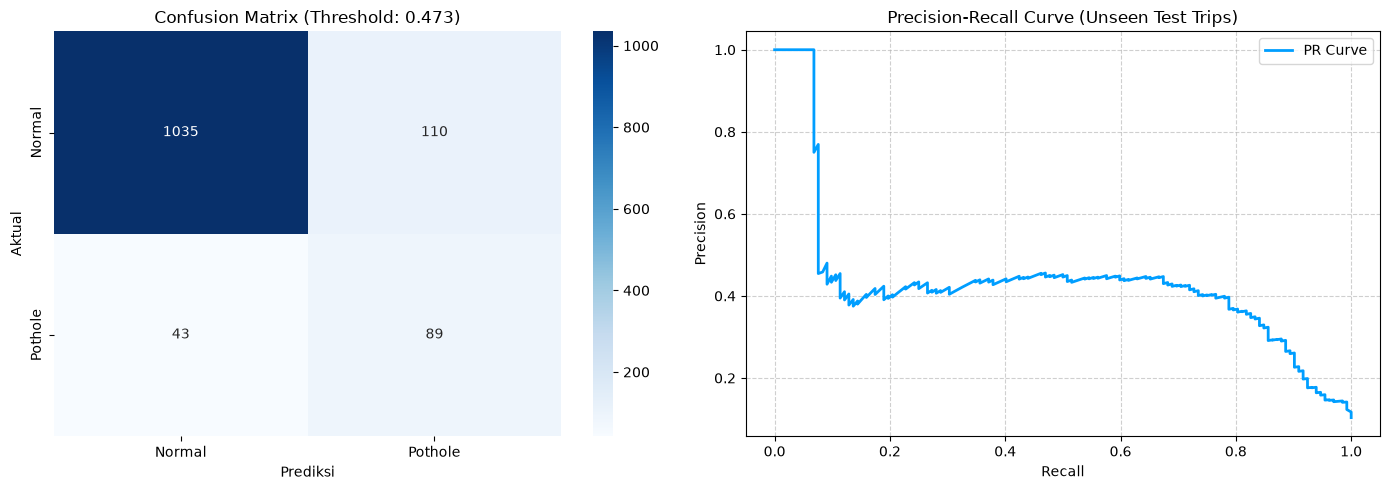

In [6]:
# 6. Visualisasi Evaluasi Model (Confusion Matrix & PR-Curve)
y_test_true = results_df['actual_label']
y_test_pred = results_df['predicted_label']
y_test_prob = results_df['pothole_probability']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test_true, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Normal', 'Pothole'], yticklabels=['Normal', 'Pothole'])
axes[0].set_title(f'Confusion Matrix (Threshold: {optimal_threshold:.3f})')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test_true, y_test_prob)
axes[1].plot(rec, prec, color='#009EFF', lw=2, label='PR Curve')
axes[1].set_title('Precision-Recall Curve (Unseen Test Trips)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# 7. Visualisasi Peta Spasial GIS (Folium Interactive Map)
df_map = results_df.dropna(subset=['latitude', 'longitude']).copy()
center_lat = df_map['latitude'].mean()
center_lon = df_map['longitude'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='OpenStreetMap')
cluster = MarkerCluster(name='Titik Deteksi').add_to(m)

for idx, row in df_map.iterrows():
    is_pothole = row['predicted_label'] == 1
    color = '#e74c3c' if is_pothole else '#3498db'
    status = '⚠️ POTHOLE' if is_pothole else '✅ NORMAL'
    
    popup_content = f"<b>{status}</b><hr><b>Trip ID:</b> {row['trip_id']}<br><b>Probabilitas:</b> {row['pothole_probability']:.2%}<br><b>Peak Shock:</b> {row['peak_shock']:.2f} m/s²<br><b>Kecepatan:</b> {row['speed']:.1f} km/h"
    
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=6 if is_pothole else 3,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8 if is_pothole else 0.4,
        popup=folium.Popup(popup_content, max_width=250),
    ).add_to(cluster)

# Heatmap Sebaran Pothole
pothole_coords = df_map[df_map['predicted_label'] == 1][['latitude', 'longitude', 'pothole_probability']].values.tolist()
if len(pothole_coords) > 0:
    HeatMap(pothole_coords, radius=15, blur=10).add_to(m)

folium.LayerControl().add_to(m)
print('Peta spasial interaktif berhasil dibuat!')
m

Peta spasial interaktif berhasil dibuat!
